# Phase 18 — Activity-tail diagnostics and independent audit
Owner: Shafin. CPU only; no new training, inference, parameter tuning or changes to the previous phases.

**Decision after Phase 17:** three-seed spread has only a weak relationship with absolute error. Marginal interval coverage is roughly near nominal, but coverage conditional on high measured activity is much lower. Independently verify the new calculations and distinguish two questions:

1. With measured activity available, do all seeds systematically underpredict high-activity elements? This is a retrospective diagnosis, not a deployable rule.
2. Without the measured activity, do predicted-activity groups or seed agreement reveal that vulnerability? Predicted-activity quintiles and spread thresholds are defined from retained calibration predictions, without audit outcomes.

This phase was chosen after seeing Phases 16–17. It is explicitly exploratory. The audit partition has already been summarized; this is not a new untouched test. Marginal conformal-style coverage does not promise 90% coverage conditional on a high observed response. Low tail coverage is not by itself proof of a conformal implementation error. No corrective model is fitted here.

In [1]:
from pathlib import Path
import os,sys,json,hashlib,math
import numpy as np,pandas as pd
from scipy.stats import pearsonr,spearmanr
ROOT=Path(r"D:\Aditta Thesis\For Shafin\Shafin's Contribution").resolve()
assert Path(sys.executable).resolve()==Path(r'C:\Users\User\.conda\envs\enhancer\python.exe').resolve()
OUT=ROOT/'phase18_outputs';OUT.mkdir(exist_ok=True)
os.environ['MPLCONFIGDIR']=str(OUT/'matplotlib_cache')
P16=ROOT/'phase16_outputs';P17=ROOT/'phase17_outputs'
def fsha(p):
 with Path(p).open('rb') as f:return hashlib.file_digest(f,'sha256').hexdigest()
def dump(name,obj):(OUT/name).write_text(json.dumps(obj,indent=2,sort_keys=True,allow_nan=False)+'\n',encoding='utf8')
def table(name,d):d.to_csv(OUT/name,index=False,float_format='%.12g')
S=pd.read_csv(P16/'ensemble_predictions_and_metadata.csv.gz')
SEEDS=pd.read_csv(P16/'seed_predictions.csv.gz')
TEST=pd.read_csv(P16/'evaluation_cohort.csv.gz')
T=pd.read_csv(ROOT/'phase14_outputs/training_only_subgroup_thresholds.csv')
PARAM=pd.read_csv(P17/'interval_calibration_parameters.csv')
INTERVAL=pd.read_csv(P17/'audit_prediction_intervals.csv.gz')
METRICS=pd.read_csv(P16/'retained_removed_metrics.csv')
spec={'name':'phase18_activity_tails_audit_v1','input_hashes':{str(p.relative_to(ROOT)):fsha(p) for p in [P16/'ensemble_predictions_and_metadata.csv.gz',P16/'seed_predictions.csv.gz',P17/'interval_calibration_parameters.csv',P17/'audit_prediction_intervals.csv.gz']},
 'activity_bands':'Phase14 training-only 20/80 percentiles','prediction_bands':'retained-calibration predicted-activity quintiles',
 'spread_threshold':'retained-calibration median SD','scope':'post-Phase17 exploratory diagnosis; no new fitting or untouched-test claim'}
dump('frozen_diagnostic_specification.json',spec)

## 1. Independently reconstruct ensemble metrics from the per-job caches
Read each authenticated per-job CSV directly and recompute the means and sample SDs, rather than trusting the aggregate ensemble file. Recompute all 16 primary/sensitivity metric rows using independent library implementations. Check the exact same IDs/targets and the previous frozen inputs.

Phase 16 inference produces float32 predictions before casting to float64 for export. Restore that original dtype after round-trip CSV parsing: sub-ulp parser differences can otherwise split tied ensemble means and change Spearman by up to approximately 2.7e-7. Confirm the restoration changes each cached value by less than 1e-13. No scientific score is rounded to conceal a discrepancy.

In [2]:
checks=[];rebuilt=[]
protocol=json.loads((P16/'frozen_protocol.json').read_text())
for cell in ['HepG2','K562']:
 for model in ['legnet','mprann']:
  for pop in ['retained','removed']:
   parts=[]
   for seed in protocol['seeds']:
    path=P16/'prediction_cache'/f'9b_{cell}_{model}_seed_{seed}_{pop}.csv'
    meta=json.loads(path.with_suffix('.json').read_text());assert fsha(path)==meta['prediction_sha256']
    a=pd.read_csv(path,float_precision='round_trip').set_index('record_id')
    restored=a.prediction.astype(np.float32).astype(float)
    assert np.max(abs(restored-a.prediction))<1e-13
    parts.append(restored.rename(seed))
   wide=pd.concat(parts,axis=1);assert wide.notna().all().all()
   g=S[S.cell_line.eq(cell)&S.model.eq(model)&S.population.eq(pop)].set_index('record_id').loc[wide.index]
   p=wide.to_numpy().mean(axis=1);sd=wide.to_numpy().std(axis=1,ddof=1)
   assert np.max(abs(p-g.prediction))<1e-10 and np.max(abs(sd-g.seed_sd))<1e-10
   rebuilt.append(pd.DataFrame({'record_id':wide.index,'cell_line':cell,'model':model,'population':pop,'prediction':p,'seed_sd':sd}))
   checks.append(dict(check='ensemble_and_SD',cell_line=cell,model=model,population=pop,n=len(g),maximum_error=float(np.max(abs(p-g.prediction)))))
REBUILT=pd.concat(rebuilt,ignore_index=True).merge(TEST,on=['record_id','cell_line','population'],validate='many_to_one')
for row in METRICS.itertuples():
 flag='eligible_primary' if row.analysis=='primary' else 'eligible_31mer_sensitivity'
 g=REBUILT[REBUILT.cell_line.eq(row.cell_line)&REBUILT.model.eq(row.model)&REBUILT.population.eq(row.population)&REBUILT[flag]]
 y=g.mean_log2_activity.to_numpy();p=g.prediction.to_numpy();error=p-y
 got={'pearson':pearsonr(y,p).statistic,'spearman':spearmanr(y,p).statistic,'mae':np.mean(abs(error)),
  'rmse':np.linalg.norm(error)/np.sqrt(len(error)),'r2':1-np.dot(error,error)/np.dot(y-y.mean(),y-y.mean())}
 assert len(g)==row.n
 for metric,value in got.items():
  diff=abs(value-getattr(row,metric));assert diff<1e-9
  checks.append(dict(check=metric,cell_line=row.cell_line,model=row.model,population=row.population,analysis=row.analysis,n=len(g),maximum_error=diff))
for rel,h in json.loads((P16/'protected_input_hashes.json').read_text()).items():assert fsha(ROOT/rel)==h
print('Independently verified all 24 cached prediction files, ensemble means/SDs, 16 metric rows and protected inputs.')

Independently verified all 24 cached prediction files, ensemble means/SDs, 16 metric rows and protected inputs.


## 2. Independently verify interval fitting and coverage
Reconstruct the finite-sample residual order statistic directly, and compare every saved endpoint and every coverage summary. Calibration and audit region/identity groups must be disjoint. The 90% nominal rate is an intended marginal target, not a conditional guarantee.

In [3]:
for row in PARAM.itertuples():
 cal=S[S.cell_line.eq(row.cell_line)&S.model.eq(row.model)&S.population.eq(row.calibration_source)&S.followup_partition.eq('calibration')&S.eligible_primary]
 scores=abs(cal.prediction.to_numpy()-cal.mean_log2_activity.to_numpy())
 if row.method=='seed_scaled':scores=scores/np.maximum(cal.seed_sd.to_numpy(),row.seed_sd_floor)
 k=min(len(scores),math.ceil((len(scores)+1)*.9));q=np.partition(scores,k-1)[k-1]
 assert abs(q-row.quantile)<1e-9
 h=INTERVAL[INTERVAL.cell_line.eq(row.cell_line)&INTERVAL.model.eq(row.model)&INTERVAL.calibration_source.eq(row.calibration_source)&INTERVAL.method.eq(row.method)]
 meta=S[S.cell_line.eq(row.cell_line)&S.model.eq(row.model)].set_index('record_id').loc[h.record_id]
 assert meta.followup_partition.eq('audit').all() and set(meta.resampling_group).isdisjoint(cal.resampling_group)
 half=np.full(len(h),q) if row.method=='constant_width' else q*np.maximum(meta.seed_sd.to_numpy(),row.seed_sd_floor)
 assert np.max(abs(h.lower.to_numpy()-(h.prediction.to_numpy()-half)))<1e-9
 assert np.max(abs(h.upper.to_numpy()-(h.prediction.to_numpy()+half)))<1e-9
 covered=(h.target>=h.lower)&(h.target<=h.upper);assert np.array_equal(covered.to_numpy(),h.covered.to_numpy())
 checks.append(dict(check='interval_quantile_and_endpoints',cell_line=row.cell_line,model=row.model,population=row.calibration_source,analysis=row.method,n=len(h),maximum_error=float(abs(q-row.quantile))))
reported=pd.read_csv(P17/'interval_audit_coverage.csv')
for row in reported.itertuples():
 h=INTERVAL[INTERVAL.cell_line.eq(row.cell_line)&INTERVAL.model.eq(row.model)&INTERVAL.calibration_source.eq(row.calibration_source)&INTERVAL.method.eq(row.method)&INTERVAL.audit_population.eq(row.audit_population)]
 assert len(h)==row.n and abs(h.covered.mean()-row.empirical_coverage)<1e-10
 assert abs((h.upper-h.lower).mean()-row.mean_width)<1e-10
table('independent_numerical_checks.csv',pd.DataFrame(checks))
print('Verified 16 fitted interval parameter sets, all interval endpoints and 32 coverage/width summaries.')

Verified 16 fitted interval parameter sets, all interval endpoints and 32 coverage/width summaries.


## 3. Observed-activity tails: consensus underprediction and low-spread misses
Activity thresholds use only the original training distribution. Restrict diagnostics to the Phase 17 audit groups. Report signed errors (prediction minus measurement), fractions of all three seeds underpredicting, and misses from the retained-calibrated constant-width interval. A low-spread miss means the interval misses despite seed spread below the retained-calibration median.

These groups require measured activity and cannot identify high-activity sequences before an assay. Apparent consensus underprediction in a group selected for high observed values also reflects regression to the mean and possible measurement noise; it does not establish a biological mechanism.

In [4]:
TAIL=[];PREDGROUP=[];edges_rows=[]
primary_intervals=INTERVAL[INTERVAL.calibration_source.eq('retained')&INTERVAL.method.eq('constant_width')].set_index(['cell_line','model','record_id'])
for (cell,model),allg in REBUILT[REBUILT.eligible_primary].groupby(['cell_line','model']):
 tr=T[T.protocol.eq('9b')&T.cell_line.eq(cell)].iloc[0]
 cal=allg[allg.population.eq('retained')&allg.followup_partition.eq('calibration')]
 spread_cut=float(cal.seed_sd.median());edges=np.quantile(cal.prediction,[.2,.4,.6,.8])
 edges_rows.append(dict(cell_line=cell,model=model,seed_sd_cutoff=spread_cut,**{f'prediction_q{q}':v for q,v in zip([20,40,60,80],edges)}))
 for pop,g in allg[allg.followup_partition.eq('audit')].groupby('population'):
  g=g.copy();g['activity_band']=np.where(g.mean_log2_activity<tr.training_activity_q20,'low',np.where(g.mean_log2_activity>tr.training_activity_q80,'high','middle'))
  g['prediction_band']=np.searchsorted(edges,g.prediction,side='right')+1
  w=SEEDS[SEEDS.cell_line.eq(cell)&SEEDS.model.eq(model)&SEEDS.population.eq(pop)].pivot(index='record_id',columns='seed',values='prediction').loc[g.record_id]
  e=w.to_numpy()-g.mean_log2_activity.to_numpy()[:,None]
  g['all_seeds_underpredict']=(e<0).all(axis=1)
  h=primary_intervals.loc[[(cell,model,i) for i in g.record_id]]
  g['covered']=h.covered.to_numpy();g['low_spread']=g.seed_sd<=spread_cut
  g['low_spread_miss']=g.low_spread&~g.covered
  g['interval_width']=(h.upper-h.lower).to_numpy()
  for family,container in [('activity_band',TAIL),('prediction_band',PREDGROUP)]:
   for band,s in g.groupby(family):
    error=s.prediction-s.mean_log2_activity
    container.append(dict(cell_line=cell,model=model,population=pop,band=band,n=len(s),suppressed=len(s)<100,
      mean_measured_activity=float(s.mean_log2_activity.mean()),mean_prediction=float(s.prediction.mean()),
      mae=float(abs(error).mean()),signed_error=float(error.mean()),mean_seed_sd=float(s.seed_sd.mean()),
      all_seeds_underpredict_fraction=float(s.all_seeds_underpredict.mean()),empirical_coverage=float(s.covered.mean()),
      low_spread_miss_fraction=float(s.low_spread_miss.mean()),fraction_of_misses_with_low_spread=float(s.loc[~s.covered,'low_spread'].mean()) if (~s.covered).any() else None,
      mean_interval_width=float(s.interval_width.mean())))
TAIL=pd.DataFrame(TAIL);PREDGROUP=pd.DataFrame(PREDGROUP)
table('observed_activity_tail_diagnostics.csv',TAIL);table('predicted_activity_group_diagnostics.csv',PREDGROUP);table('calibration_prediction_group_edges.csv',pd.DataFrame(edges_rows))
print('Observed high-activity groups:');print(TAIL[TAIL.band.eq('high')].round(5).to_string(index=False))
print('Predicted-activity quintile coverage:');print(PREDGROUP[['cell_line','model','population','band','n','empirical_coverage','signed_error']].round(5).to_string(index=False))

Observed high-activity groups:
cell_line  model population band    n  suppressed  mean_measured_activity  mean_prediction     mae  signed_error  mean_seed_sd  all_seeds_underpredict_fraction  empirical_coverage  low_spread_miss_fraction  fraction_of_misses_with_low_spread  mean_interval_width
    HepG2 legnet    removed high 1153       False                 0.84774          0.14192 0.75160      -0.70582       0.19507                          0.81873             0.60364                   0.15872                             0.40044              1.60992
    HepG2 legnet   retained high 1258       False                 0.88286          0.15739 0.77630      -0.72547       0.19879                          0.81558             0.57393                   0.16773                             0.39366              1.60992
    HepG2 mprann    removed high 1153       False                 0.84774          0.11140 0.75912      -0.73634       0.17826                          0.85169             0.61405 

## 4. Save diagnostic figures and next-step decision
No interval was modified in response to these results. Any fitted correction or learned uncertainty model should be developed on an appropriate training/calibration partition and evaluated on new reserved data. For the present paper, report weak seed-spread reliability and marginal-versus-subgroup coverage honestly. Complete the written evidence package; keep the DNABERT-2 removed-population comparison pending its actual saved checkpoints.

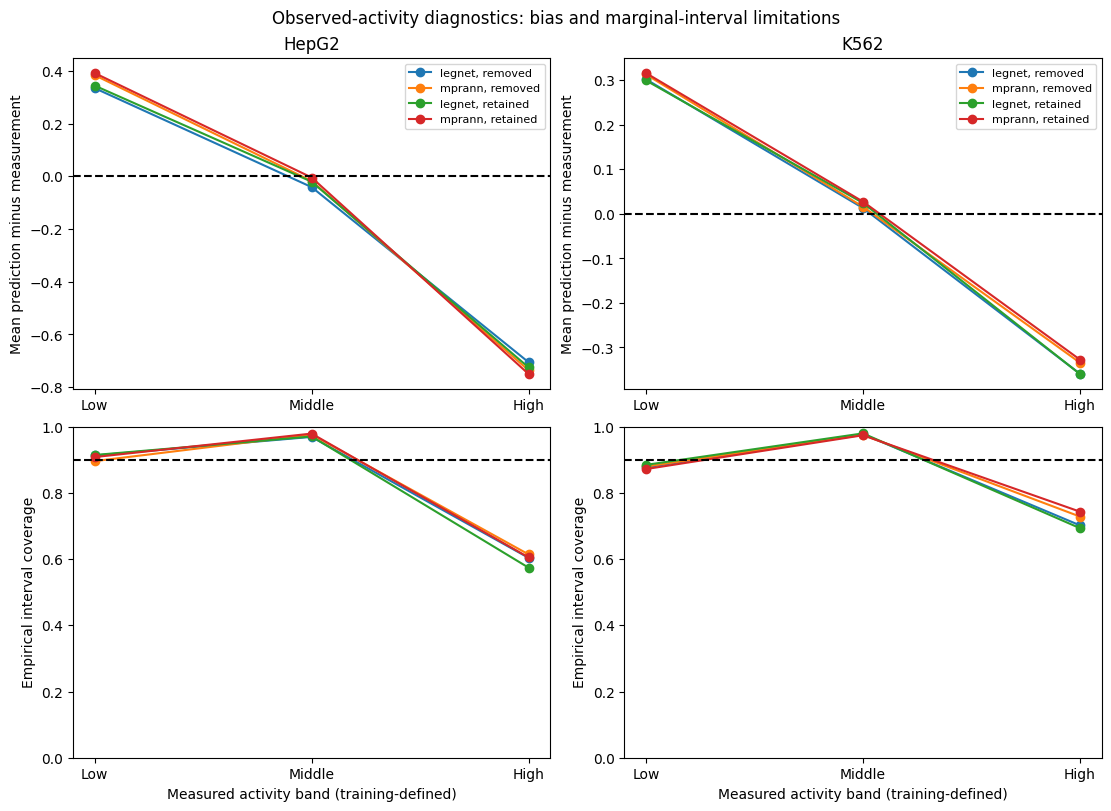

In [5]:
import matplotlib.pyplot as plt
fig,axes=plt.subplots(2,2,figsize=(11,8),constrained_layout=True)
for j,cell in enumerate(['HepG2','K562']):
 for (pop,model),g in TAIL[TAIL.cell_line.eq(cell)].groupby(['population','model']):
  g=g.set_index('band').loc[['low','middle','high']]
  axes[0,j].plot(['Low','Middle','High'],g.signed_error,marker='o',label=f'{model}, {pop}')
  axes[1,j].plot(['Low','Middle','High'],g.empirical_coverage,marker='o',label=f'{model}, {pop}')
 axes[0,j].axhline(0,color='black',linestyle='--');axes[0,j].set_title(cell);axes[0,j].set_ylabel('Mean prediction minus measurement');axes[0,j].legend(fontsize=8)
 axes[1,j].axhline(.9,color='black',linestyle='--');axes[1,j].set_ylim(0,1);axes[1,j].set_ylabel('Empirical interval coverage');axes[1,j].set_xlabel('Measured activity band (training-defined)')
fig.suptitle('Observed-activity diagnostics: bias and marginal-interval limitations')
fig.savefig(OUT/'activity_tail_bias_and_coverage.png',dpi=180);fig.savefig(OUT/'activity_tail_bias_and_coverage.pdf');plt.show()
dump('phase18_summary.json',dict(status='completed_for_CNNs_DNABERT2_pending',numerical_checks=len(checks),
 maximum_numerical_difference=float(pd.DataFrame(checks).maximum_error.max()),training_launched=False,
 interval_recalibration_performed=False,scope='Retrospective diagnostics; not individual or conditional coverage guarantees',
 outputs={p.name:fsha(p) for p in OUT.iterdir() if p.is_file() and p.name!='phase18_summary.json'}))